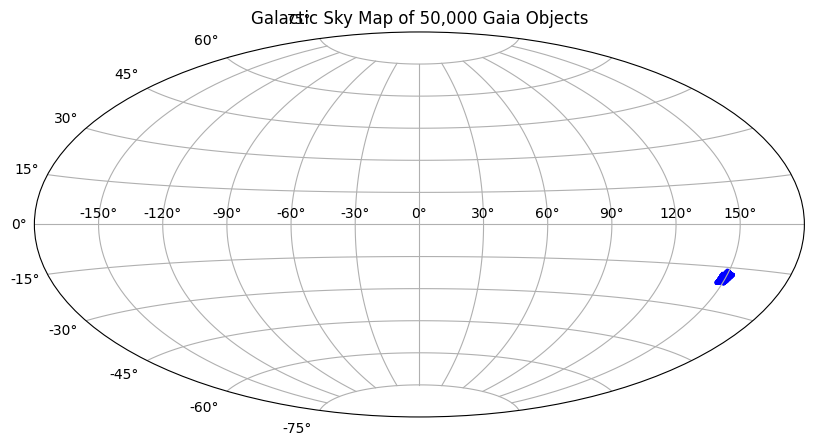

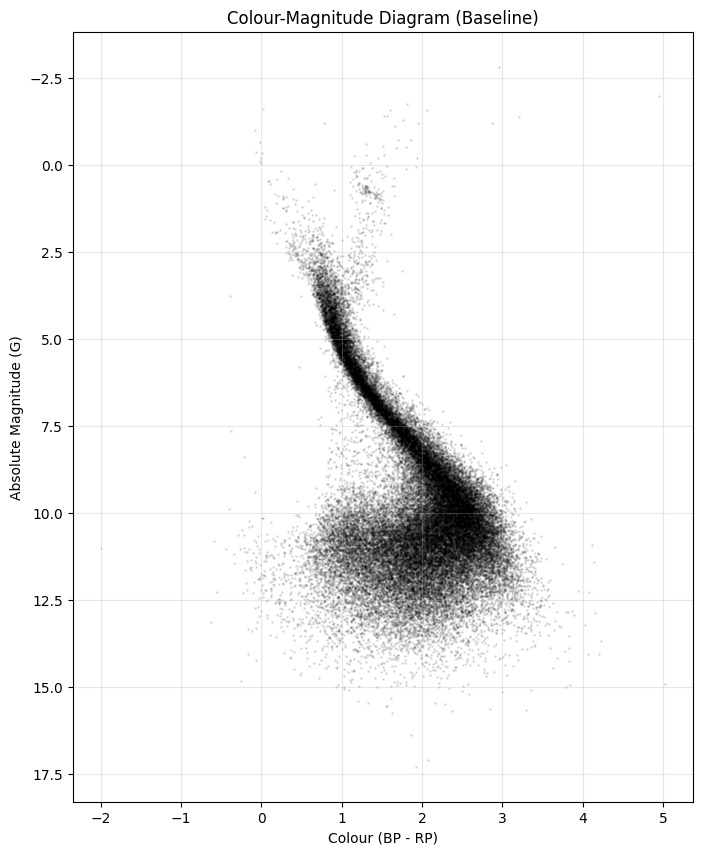

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
from astropy import units as u

# 1. Load the data
gaia_df = pd.read_csv('../data/raw/gaia_50k.csv')

# 2. Astropy Coordinates (Converting RA/DEC to a Sky Map)
coords = SkyCoord(ra=gaia_df['ra'].values * u.degree, 
                  dec=gaia_df['dec'].values * u.degree, 
                  frame='icrs')

# Convert to Galactic coordinates for a better physical representation
galactic_coords = coords.galactic

plt.figure(figsize=(10, 5))
plt.subplot(111, projection='aitoff')
plt.grid(True)
# Convert radians for the aitoff projection
plt.scatter(galactic_coords.l.wrap_at('180d').radian, 
            galactic_coords.b.radian, 
            s=1, alpha=0.1, color='blue')
plt.title("Galactic Sky Map of 50,000 Gaia Objects")
plt.show()

# 3. Feature Engineering: Absolute Magnitude
# Formula: M = m + 5*log10(parallax) - 10
gaia_df['absolute_magnitude_g'] = gaia_df['phot_g_mean_mag'] + 5 * np.log10(gaia_df['parallax']) - 10

# 4. The Colour-Magnitude Diagram (HR Diagram)
plt.figure(figsize=(8, 10))
plt.scatter(gaia_df['bp_rp'], gaia_df['absolute_magnitude_g'], s=1, alpha=0.1, color='black')

# In astronomy, brighter objects have LOWER magnitude numbers, so we invert the Y-axis.
plt.gca().invert_yaxis()

plt.title("Colour-Magnitude Diagram (Baseline)")
plt.xlabel("Colour (BP - RP)")
plt.ylabel("Absolute Magnitude (G)")
plt.grid(alpha=0.3)
plt.show()